In [200]:
!pip install emoji

In [220]:
!pip show emoji

Name: emoji
Version: 2.16.0
Summary: Emoji for Python
Home-page: https://github.com/carpedm20/emoji/
Author: 
Author-email: Taehoon Kim <carpedm20@gmail.com>, Kevin Wurster <wursterk@gmail.com>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: 
Required-by: 


In [201]:
#những thư viện cơ bản
import numpy as np
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import re
#kiểm tra emoji
import emoji

#những thư viện liên quan đến scikit learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

In [202]:
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [203]:
train_pq = pd.read_parquet('train-00000-of-00001-daf190ce720b3dbb.parquet')
test_pq= pd.read_parquet('test-00000-of-00001-fa9b3e8ade89a333.parquet')
e_sms = pd.read_csv('email.csv').drop_duplicates()
spam_ham = pd.read_csv('spam_ham_dataset.csv').drop(columns=['Unnamed: 0']).drop_duplicates()



In [204]:

# Khởi tạo bộ Stemmer để chuẩn hóa từ về dạng gốc
stemmer = nltk.stem.PorterStemmer()

def is_emoji(text):
    for char in text:
        if emoji.is_emoji(char):
            return True
    return False

def clean_emoji(text):
    for char in text:
        if emoji.is_emoji(char):
            text = text.replace(char, 'EMOJI')
    return text

def clean_url(text):
    urls = re.findall(r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+', text)
    for url in urls:
        text = text.replace(url, 'URL')
    return text

def clean_html(text):
    html_tags = re.findall(r'<[^>]+>', text)
    for tag in html_tags:
        text = text.replace(tag, 'HTML')
    return text

def clean_number(text):
    numbers = re.findall(r'\d+', text)
    for number in numbers:
        text = text.replace(number, 'NUMBER')
    return text

def clean_email_address(text):
    email_addresses = re.findall(r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}',text)
    for email in email_addresses:
        text = text.replace(email, 'EMAIL')
    return text

def clean_special_characters(text):
    # Giữ chữ cái, khoảng trắng và dấu nháy trong từ
    text = re.sub(r"[^a-zA-Z\s']", ' ', text)
    return text

def normalize_word(text):
    tmp = text.split()
    return ' '.join(stemmer.stem(word) for word in tmp)

def remove_stopwords(text):
    stop_words = set(nltk.corpus.stopwords.words('english'))
    tmp = text.split()
    return ' '.join(word for word in tmp if word not in stop_words)

def clean_text(text):
    text = clean_emoji(text)
    # text = clean_url(text)
    text = clean_html(text)
    text = clean_number(text)
    text = clean_email_address(text)
    text = text.lower()
    text = normalize_word(text)
    text = remove_stopwords(text)
    text = clean_special_characters(text)
    return text

def label_to_num(text):
    return 1 if text == 'spam' else 0

test_text = train_pq['text'][12]
print("Văn bản gốc:")
print(test_text)
print("\nVăn bản sau khi làm sạch:")
print(clean_text(test_text))

Văn bản gốc:
HEY EVERYONE!!! 👋👋👋

Are you Tired 😴 of boring 😒 posts?? Me too!!! That's why I'm here to spice things up on this app 🌶️🌶️🌶️!!!

Are you looking for a way to lose weight 💪🏃‍♀️🥦 and gain muscle 💪💪💪? Do not worry, I have the solution for you!!! 🙌🙌🙌

Introducing the amazing 🤩🤩🤩 diet pills that will make you lose weight in

Văn bản sau khi làm sạch:
hey everyone    emojiemojiemoji tire emoji bore emoji posts   too    that' whi spice thing thi app emoji emoji emoji     look way lose weight emojiemoji emoji emoji gain muscl emojiemojiemoji  worry  solut you    emojiemojiemoji introduc amaz emojiemojiemoji diet pill make lose weight


Tiền sử lý đầu vào, ta loại bỏ hậu tố sử dụng stemming (có thể sử dụng lemmatiztion nhưng tôi sẽ ưu tiên tốc độ hơn), loại bỏ những stop word, đánh dấu những khoảng có số, emoji hoặc những điểm đặc biệt. đưa về plain text để chuẩn bị TF-IDF

In [205]:
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import GroupShuffleSplit

# robust label mapping: handles 'spam'/'ham' strings and 0/1 integers
def to_num(x):
    return 1 if str(x).strip().lower() in ('spam', '1') else 0

# 1. one pool with a source column (no splitting yet)
sms = (e_sms[e_sms['Category'].isin(['ham', 'spam'])]
       .rename(columns={'Message': 'text', 'Category': 'label'}))
sms['source'] = 'sms'

enron = spam_ham.drop(columns=['label']).rename(columns={'label_num': 'label'})
enron['source'] = 'enron'

pq1 = train_pq[['text', 'label']].copy(); pq1['source'] = 'pq'
pq2 = test_pq[['text', 'label']].copy();  pq2['source'] = 'pq'

all_df = pd.concat([d[['text', 'label', 'source']] for d in (sms, enron, pq1, pq2)],
                   ignore_index=True)
all_df = all_df.dropna(subset=['text'])
all_df['label'] = all_df['label'].map(to_num)

# 2. clean, then dedupe on the CLEANED text
all_df['text'] = all_df['text'].apply(clean_text)
all_df = all_df[all_df['text'].str.strip() != ''].drop_duplicates('text').reset_index(drop=True)

# 3. cluster near-duplicates (cosine >= 0.9), in chunks to save memory
X = TfidfVectorizer(min_df=2, max_df=0.5).fit_transform(all_df['text'])
rows, cols = [], []
for i in range(0, X.shape[0], 2000):
    sim = (X[i:i+2000] @ X.T).toarray()
    r, c = np.where(sim >= 0.9)
    rows.append(r + i); cols.append(c)
rows, cols = np.concatenate(rows), np.concatenate(cols)
graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(X.shape[0],) * 2)
_, groups = connected_components(graph, directed=False)

# 4. split so each cluster stays on one side
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(all_df, groups=groups))
train, test = all_df.iloc[tr_idx].copy(), all_df.iloc[te_idx].copy()

print(train['label'].value_counts(), test['label'].value_counts())
print(all_df.groupby('source')['label'].agg(['count', 'mean']))   # spam ratio per source

label
0    10388
1     6025
Name: count, dtype: int64 label
0    2526
1    1552
Name: count, dtype: int64
        count      mean
source                 
enron    4710  0.309979
pq      10656  0.516047
sms      5125  0.120585


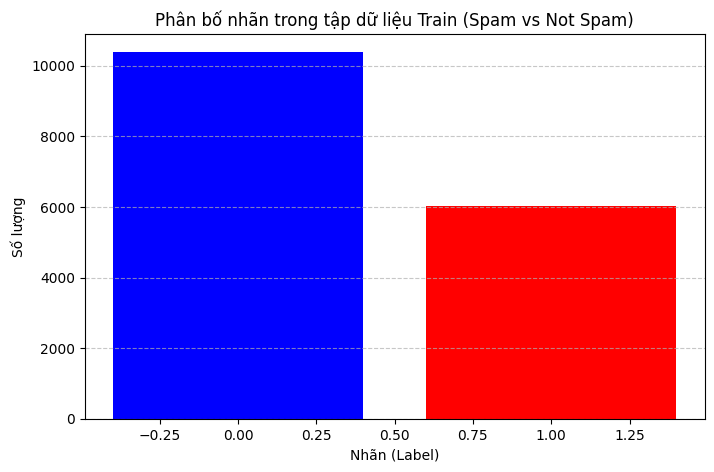

label
0    10388
1     6025
Name: count, dtype: int64


In [206]:
# Đếm số lượng của từng nhãn (spam vs not_spam)
label_counts = train['label'].value_counts()

# Vẽ biểu đồ cột trực quan hóa
plt.figure(figsize=(8, 5))
plt.bar(label_counts.index, label_counts.values, color=['blue', 'red'])
plt.title('Phân bố nhãn trong tập dữ liệu Train (Spam vs Not Spam)')
plt.xlabel('Nhãn (Label)')
plt.ylabel('Số lượng')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print(label_counts)

In [207]:
train = train.dropna()
text = train['text']
label = train['label']

In [208]:
tdf_word = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    max_features=20000,
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
)
tdf_pharse = TfidfVectorizer(
    lowercase=False,
    analyzer='char_wb',
    ngram_range=(2,5),
    max_features=20000,
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
)

x_word = tdf_word.fit_transform(text)
x_pharse = tdf_pharse.fit_transform(text)

x_word.shape, x_pharse.shape

((16413, 20000), (16413, 20000))

In [209]:
model_word = LogisticRegression(max_iter=1000, class_weight='balanced')
model_pharse = LogisticRegression(max_iter=1000, class_weight='balanced')

model_word.fit(x_word, label)
model_pharse.fit(x_pharse, label)



LogisticRegression(class_weight='balanced', max_iter=1000)

In [210]:
test = test.dropna()
test_word = tdf_word.transform(test['text'])
test_pharse = tdf_pharse.transform(test['text'])
test_ans = test['label']

In [211]:
for m in (model_pharse, model_word):
    pred = m.predict(test_word if m == model_word else test_pharse)
    print('word' if m == model_word else 'pharse')
    print(accuracy_score(test_ans, pred))
    print(classification_report(test_ans, pred))
    print(confusion_matrix(test_ans, pred))
#

pharse
0.9813634134379597
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2526
           1       0.98      0.97      0.98      1552

    accuracy                           0.98      4078
   macro avg       0.98      0.98      0.98      4078
weighted avg       0.98      0.98      0.98      4078

[[2497   29]
 [  47 1505]]
word
0.9823442864149092
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2526
           1       0.98      0.97      0.98      1552

    accuracy                           0.98      4078
   macro avg       0.98      0.98      0.98      4078
weighted avg       0.98      0.98      0.98      4078

[[2497   29]
 [  43 1509]]


In [212]:
for src, g in test.groupby('source'):
    print('==', src, len(g))
    for name, m, vec in (('word', model_word, tdf_word), ('char', model_pharse, tdf_pharse)):
        pred = m.predict(vec.transform(g['text']))
        print(name, round(accuracy_score(g['label'], pred), 4))
        print(confusion_matrix(g['label'], pred))

== enron 926
word 0.959
[[619  16]
 [ 22 269]]
char 0.9644
[[613  22]
 [ 11 280]]
== pq 2129
word 0.9953
[[ 997    2]
 [   8 1122]]
char 0.9939
[[ 997    2]
 [  11 1119]]
== sms 1023
word 0.9765
[[881  11]
 [ 13 118]]
char 0.9707
[[887   5]
 [ 25 106]]


In [213]:
super_test = pd.read_csv('email_spam_phishing_ham_99.csv')
super_test = super_test.dropna()

# Áp dụng tiền xử lý văn bản giống như lúc train
super_test_cleaned = super_test['text'].apply(clean_text)

super_test_word = tdf_word.transform(super_test_cleaned)
super_test_pharse = tdf_pharse.transform(super_test_cleaned)
super_test_ans = super_test['label']

In [228]:
print('word')
for m, name, test_feat in [
    (model_word, 'word', super_test_word),
    (model_pharse, 'phrase', super_test_pharse)
]:
    # Lấy xác suất của nhãn spam (cột có chỉ mục 1)
    probs = m.predict_proba(test_feat)[:, 1]
    # Ngưỡng phân loại là 0.4
    pred = (probs > 0.4).astype(int)

    print(f"\n=== Model {name} (Threshold 0.4) ===")
    print("Accuracy:", accuracy_score(super_test_ans, pred))
    print(classification_report(super_test_ans, pred))
    print(confusion_matrix(super_test_ans, pred))

word

=== Model word (Threshold 0.4) ===
Accuracy: 0.8383838383838383
              precision    recall  f1-score   support

           0       0.74      0.79      0.76        33
           1       0.89      0.86      0.88        66

    accuracy                           0.84        99
   macro avg       0.82      0.83      0.82        99
weighted avg       0.84      0.84      0.84        99

[[26  7]
 [ 9 57]]

=== Model phrase (Threshold 0.4) ===
Accuracy: 0.8181818181818182
              precision    recall  f1-score   support

           0       0.73      0.73      0.73        33
           1       0.86      0.86      0.86        66

    accuracy                           0.82        99
   macro avg       0.80      0.80      0.80        99
weighted avg       0.82      0.82      0.82        99

[[24  9]
 [ 9 57]]


In [215]:
   from sklearn.metrics import roc_auc_score
   p = model_pharse.predict_proba(tdf_pharse.transform(super_test['text'].apply(clean_text)))[:,1]
   print(roc_auc_score(super_test['label'], p))

0.869605142332415


In [219]:
small_test = '''
From:”People’s Bank”
Subject: Offi cial information for all People’s Bank clients.
Dear People’s Bank Client,
To provide our customers the most effective and secure online access to their accounts, we are continually upgrading our online services. As we add new features and enhancements to our service, there are certain browser
versions which will not support these system upgrades. As many customers already know, Microsoft Internet
Explorer has signifi cant ‘holes’ or vulnerabilities that virus creators can easily take advantage of.
In order to further protect your account, we have introduced some new important security standards and browser
requirements. People’s Bank security systems require that you test your browser now to see if meets the requirements to People’s Bank Online Banking.
Please https://PeopleBankAccount.com Sign on to Internet Banking in order to verify security update
installation. This security update will be effective immediately. In the meantime, some of the Internet Banking
services may not be available.
Sincerly yours, People’s Bank Team!
'''

small_test_cleaned = clean_text(small_test)
small_test_word = tdf_word.transform([small_test_cleaned])
small_test_pharse = tdf_pharse.transform([small_test_cleaned])
print(model_word.predict_proba(small_test_word))
print(model_pharse.predict_proba(small_test_pharse))

[[0.24926487 0.75073513]]
[[0.16264295 0.83735705]]


In [223]:
import joblib
joblib.dump(model_word, 'model_word.joblib')
joblib.dump(model_pharse, 'model_pharse.joblib')
joblib.dump(tdf_word, 'tdf_word.joblib')
joblib.dump(tdf_pharse, 'tdf_pharse.joblib')


['tdf_pharse.joblib']